# Angular clustering w(theta) — DP2 Object catalog + photo-z

Builds a MagLim-style lens galaxy sample from Rubin DP2, masks it with the DP2 survey
property maps, generates randoms, measures the raw and systematics-decontaminated angular
correlation function w(theta) in tomographic bins with TreeCorr, and measures the angular
power spectrum C(ell), both naively and with proper NaMaster deconvolution and template
deprojection.

**Region:** a contiguous ~100-300 deg² patch of the main (wide, non-DDF) coadd footprint,
centered on the Week 7 coordinates (345, -8.2). Increase `RADIUS_DEG` to grow the patch, up
to the full footprint.

**Sections:**
1. Setup
2. Galaxy selection
3. Masking and systematics templates
4. Angular correlation function
5. Angular power spectrum

**Data products:** `dp2.Object` (TAP), `object_photoz` (LSDB/HATS), DP2 survey property maps
(Butler).

## 1. Setup

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp
import hpgeom as hpg
import healsparse
import treecorr
import lsdb
from upath import UPath
from lsst.daf.butler import Butler
from lsst.rsp import RSPDiscovery


### 1.1. Region and selection parameters

`RADIUS_DEG` sets a circular query region of area `pi * RADIUS_DEG**2`. Three presets are
noted in the cell below (1, 3, 6 deg radius); the full-footprint default is ~113 deg², in the
middle of the requested 100-300 deg² range, chosen to keep the TAP query and the pandas/LSDB
join comfortably within class time. Ambitious students can grow `RADIUS_DEG` toward the full
footprint — see the note in Section 1.3 about the join's ~1M row guideline.

`FAINT_PRECUT` is a loose faint-end cut applied at the TAP stage only, to bound the amount of
data pulled before the photo-z join. It is well below the typical depth where the exact
MagLim relation would cut anyway (`i = 4*z_phot + 18` reaches 23 mag only for `z_phot > 1.25`),
so it should not bias the final sample for a low-to-moderate redshift lens selection. The
true MagLim-style cut is re-applied exactly, using the joined photo-z, in Section 2.

`FETCH_FULL_SYSTEMATICS` controls how many Butler survey-property maps Section 3 fetches.
`False` fetches only the i-band depth map — the one map the footprint mask actually needs —
which is both faster and enough to get a properly masked w(theta). `True` additionally
fetches PSF size, sky noise, exposure time, and griz coverage, which the systematics
diagnostics, weights, and power-spectrum template deprojection in Sections 3 and 5 need to
use the full set. Either way, every map fetch is cached to disk under `MAP_CACHE_DIR` (see
Section 3.2), so repeated runs with the same parameters skip the slow Butler I/O entirely
after the first.

In [2]:
FETCH_FULL_SYSTEMATICS = True  # True: all 7 Butler maps / 6 systematics templates

RA_CENTER = 345.0
DEC_CENTER = -8.2
# Region size presets (radius in degrees, area in deg^2):
#   1.0 deg ~  3 deg^2   - fast end-to-end sanity check
#   3.0 deg ~ 28 deg^2   - medium: confirms the LSDB join scales past ~1M rows
#   6.0 deg ~113 deg^2   - full footprint
RADIUS_DEG = 6.0

BAND = 'i'
MAG_BRIGHT = 17.5
FAINT_PRECUT = 23.0
MAGLIM_SLOPE = 4.0
MAGLIM_INTERCEPT = 18.0

N_ZBINS = 4
Z_EDGES = np.linspace(0.0, 1.0, N_ZBINS + 1)

MASK_NSIDE = 4096
DIAG_NSIDE = 512
DEPTH_MARGIN_MAG = 1.0
STAR_MAG_BRIGHT = 17.5
STAR_MAG_FAINT = 21.0
STELLAR_DENSITY_PERCENTILE = 90.0

MAP_CACHE_DIR = os.path.expanduser('~/notebooks/.map_cache')

RAND_FACTOR = 15
MAX_RANDOMS = 2_000_000

TC_MIN_SEP_ARCMIN = 1.0
# Keep max_sep well under the patch radius: near half the radius, galaxy/random pairs close
# to the footprint boundary are incompletely sampled, which biases the largest-scale bins far
# beyond what their (shot-noise-only) error bars suggest. 0.2x is a safer margin than 0.5x.
TC_MAX_SEP_ARCMIN = min(250.0, RADIUS_DEG * 60.0 * 0.2)
TC_NBINS = 15

area_deg2 = np.pi * RADIUS_DEG**2
print('Query region: {:.2f} deg radius, {:.2f} deg^2'.format(RADIUS_DEG, area_deg2))
print('Systematics maps:', 'all 7 (full)' if FETCH_FULL_SYSTEMATICS else 'i-band depth only')


Query region: 6.00 deg radius, 113.10 deg^2
Systematics maps: all 7 (full)


### 1.2. Connect to the TAP service

In [3]:
discovery = RSPDiscovery("dp2")
service = discovery.get_tap_client()
assert service is not None


def run_query(query):
    """Submit an ADQL query as an async TAP job and return an astropy table."""
    job = service.submit_job(query)
    job.run()
    job.wait(phases=['COMPLETED', 'ERROR'])
    print('Job phase is', job.phase)
    if job.phase == 'ERROR':
        job.raise_if_error()
    assert job.phase == 'COMPLETED'
    table = job.fetch_result().to_table()
    job.delete()
    return table


### 1.3. Load precomputed data if available

Section 2 (the TAP query, photo-z join, and MagLim cut) is the slow, failure-prone part of
this notebook at full scale — the full region pulls millions of objects, well past the
~1 million row guideline for the in-memory LSDB join. `prepare_data.py` runs that part once
and saves the result to `data/`; if a cache is found there that matches the current
parameters (checked against `data/meta.json`), load it directly and skip straight to the
mask in Section 3. A mismatched or missing cache just falls back to running Section 2 live,
same as before. A live run also writes its own result to this same cache afterward, so it
stays usable either way.

In [4]:
USE_PRECOMPUTED_DATA = True
PRECOMPUTED_DATA_DIR = 'data'

current_params = {
    'ra_center': RA_CENTER, 'dec_center': DEC_CENTER, 'radius_deg': RADIUS_DEG,
    'band': BAND, 'mag_bright': MAG_BRIGHT, 'faint_precut': FAINT_PRECUT,
    'maglim_slope': MAGLIM_SLOPE, 'maglim_intercept': MAGLIM_INTERCEPT,
    'n_zbins': N_ZBINS, 'z_max': float(Z_EDGES[-1]),
}

data_loaded_from_cache = False
if USE_PRECOMPUTED_DATA:
    meta_path = os.path.join(PRECOMPUTED_DATA_DIR, 'meta.json')
    objects_path = os.path.join(PRECOMPUTED_DATA_DIR, 'objects.parquet')
    galaxies_path = os.path.join(PRECOMPUTED_DATA_DIR, 'galaxies.parquet')
    if os.path.exists(meta_path) and os.path.exists(objects_path) and os.path.exists(galaxies_path):
        with open(meta_path) as f:
            cached_params = json.load(f)
        mismatched = {k: (cached_params.get(k), v) for k, v in current_params.items()
                     if cached_params.get(k) != v}
        if mismatched:
            print('Precomputed data in {!r} does not match current parameters, '
                 'ignoring it and running the live pipeline:'.format(PRECOMPUTED_DATA_DIR))
            for k, (cached, now) in mismatched.items():
                print('  {}: cached={}, current={}'.format(k, cached, now))
        else:
            obj_df_renamed = pd.read_parquet(objects_path)
            galaxies = pd.read_parquet(galaxies_path)
            PZ_CODE = cached_params['pz_code']
            pz_col = cached_params['pz_col']
            data_loaded_from_cache = True
            print('Loaded precomputed data from {!r}: {} objects, {} galaxies'.format(
                PRECOMPUTED_DATA_DIR, cached_params['n_objects'], cached_params['n_galaxies']))
    else:
        print('No precomputed data found in {!r}; running the live pipeline.'.format(
            PRECOMPUTED_DATA_DIR))


Loaded precomputed data from 'data': 3433204 objects, 180237 galaxies


## 2. Galaxy selection

Select extended sources with clean i-band photometry flags, join photo-z, and apply a
MagLim-style cut, split into tomographic bins.

### 2.1. Query the Object catalog

Extended sources with clean i-band photometry flags, in the region, between the bright limit
and the faint pre-cut. The flag set follows the
[DP2 flag use examples](https://dp2.lsst.io/products/flags/flag_usage.html), with
`{band}_psfFlux_flag` swapped for `{band}_cModel_flag` since the selection is built on
CModel photometry (the recommended substitution for whichever flux type is actually used).

In [5]:
if not data_loaded_from_cache:
    columns = [
        'objectId', 'coord_ra', 'coord_dec', 'refExtendedness', 'ebv',
        '{0}_cModelMag'.format(BAND), '{0}_cModelMagErr'.format(BAND),
        '{0}_inputCount'.format(BAND), '{0}_cModel_flag'.format(BAND),
        '{0}_invalidPsfFlag'.format(BAND),
        '{0}_pixelFlags_saturatedCenter'.format(BAND),
        '{0}_pixelFlags_interpolatedCenter'.format(BAND),
    ]

    query = (
        "SELECT " + ", ".join(columns) + " "
        "FROM dp2.Object "
        "WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), "
        "CIRCLE('ICRS', {ra}, {dec}, {radius})) = 1 "
        "AND refExtendedness = 1 "
        "AND {b}_inputCount > 0 "
        "AND {b}_cModel_flag = 0 "
        "AND {b}_invalidPsfFlag = 0 "
        "AND {b}_pixelFlags_saturatedCenter = 0 "
        "AND {b}_pixelFlags_interpolatedCenter = 0 "
        "AND {b}_cModelMag > {bright} "
        "AND {b}_cModelMag < {faint}"
    ).format(ra=RA_CENTER, dec=DEC_CENTER, radius=RADIUS_DEG, b=BAND,
             bright=MAG_BRIGHT, faint=FAINT_PRECUT)
    print(query)

    obj_table = run_query(query)
    obj_df = obj_table.to_pandas()
    print(len(obj_df), 'extended, clean-flag objects in the region')

    MAX_JOIN_ROWS = 1_000_000
    if len(obj_df) > MAX_JOIN_ROWS:
        print('Warning: {} rows exceeds the recommended size for an in-memory LSDB join '
              '({}). Reduce RADIUS_DEG or tighten FAINT_PRECUT before continuing.'
              .format(len(obj_df), MAX_JOIN_ROWS))


### 2.2. Join photo-z on `objectId`

DP2 photo-z estimates are distributed only as an LSDB/HATS catalog (`object_photoz`), not as
a TAP-joinable table. Convert the Object query result to an LSDB catalog, open the photo-z
catalog over the same region, and do an inner join on `objectId`.

In [6]:
if not data_loaded_from_cache:
    base_path = UPath("/rubin/lsdb_data/dp2")
    obj_df_renamed = obj_df.rename(columns={'coord_ra': 'ra', 'coord_dec': 'dec'})
    obj_cat = lsdb.from_dataframe(obj_df_renamed, catalog_name="object")

    pz_cat_full = lsdb.open_catalog(base_path / "object_photoz")
    pz_codes = sorted({col.split('_')[0] for col in pz_cat_full.columns if col.endswith('_z_best')})
    print('Available photo-z estimators:', pz_codes)
    PZ_CODE = pz_codes[0]
    pz_col = '{}_z_median'.format(PZ_CODE)
    print('Using', pz_col, 'as z_phot')

    pz_cat = lsdb.open_catalog(base_path / "object_photoz",
                               columns=['objectId', 'ra', 'dec', pz_col])
    pz_cat_region = pz_cat.cone_search(ra=RA_CENTER, dec=DEC_CENTER,
                                       radius_arcsec=RADIUS_DEG * 3600.0)
    joined_cat = pz_cat_region.join(
        obj_cat,
        left_on='objectId',
        right_on='objectId',
        suffix_method='all_columns',
    )
    clustering_df = joined_cat.compute()
    print(len(clustering_df), 'objects with both Object and photo-z measurements')


### 2.3. Apply the MagLim-style cut and split into tomographic bins

In [7]:
if not data_loaded_from_cache:
    i_col = '{0}_cModelMag_object'.format(BAND)
    z_col = '{0}_object_photoz'.format(pz_col)

    clustering_df = clustering_df.rename(columns={
        i_col: 'i_mag',
        z_col: 'z_phot',
        'ebv_object': 'ebv',
        'objectId_object': 'objectId',
        'ra_object': 'ra',
        'dec_object': 'dec',
    })

    maglim_cut = (
        (clustering_df['i_mag'] > MAG_BRIGHT)
        & (clustering_df['i_mag'] < MAGLIM_SLOPE * clustering_df['z_phot'] + MAGLIM_INTERCEPT)
        & (clustering_df['z_phot'] >= Z_EDGES[0])
        & (clustering_df['z_phot'] < Z_EDGES[-1])
    )
    galaxies = clustering_df.loc[maglim_cut,
                                 ['objectId', 'ra', 'dec', 'i_mag', 'z_phot', 'ebv']].reset_index(drop=True)
    # clustering_df comes from an LSDB .compute(), as a nested_pandas.NestedFrame; cast back
    # to a plain DataFrame so it round-trips through parquet like any other pandas object.
    galaxies = pd.DataFrame(galaxies)
    galaxies['zbin'] = np.digitize(galaxies['z_phot'], Z_EDGES[1:-1])
    print(len(galaxies), 'galaxies pass the MagLim-style cut and lie in [{:.2f}, {:.2f})'.format(
        Z_EDGES[0], Z_EDGES[-1]))
    for b in range(N_ZBINS):
        print('  bin {}: {:.2f} <= z < {:.2f}, {} galaxies'.format(
            b, Z_EDGES[b], Z_EDGES[b + 1], np.sum(galaxies['zbin'] == b)))

    os.makedirs(PRECOMPUTED_DATA_DIR, exist_ok=True)
    obj_df_renamed.to_parquet(os.path.join(PRECOMPUTED_DATA_DIR, 'objects.parquet'), index=False)
    galaxies.to_parquet(os.path.join(PRECOMPUTED_DATA_DIR, 'galaxies.parquet'), index=False)
    cache_meta = dict(current_params)
    cache_meta.update({'pz_code': PZ_CODE, 'pz_col': pz_col,
                       'n_objects': len(obj_df_renamed), 'n_galaxies': len(galaxies)})
    with open(os.path.join(PRECOMPUTED_DATA_DIR, 'meta.json'), 'w') as f:
        json.dump(cache_meta, f, indent=2)
    print('Saved precomputed data to', PRECOMPUTED_DATA_DIR)


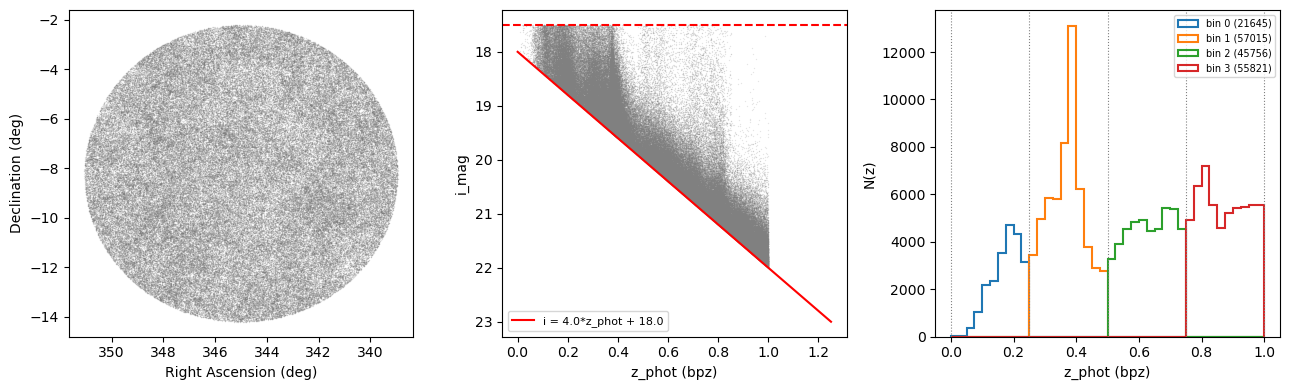

In [8]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4))

ax1.plot(galaxies['ra'], galaxies['dec'], 'o', ms=1, mew=0, alpha=0.2, color='grey')
ax1.set_xlabel('Right Ascension (deg)')
ax1.set_ylabel('Declination (deg)')
ax1.invert_xaxis()

ax2.plot(galaxies['z_phot'], galaxies['i_mag'], 'o', ms=1, mew=0, alpha=0.2, color='grey')
z_line = np.linspace(0, (23 - MAGLIM_INTERCEPT) / MAGLIM_SLOPE, 100)
ax2.plot(z_line, MAGLIM_SLOPE * z_line + MAGLIM_INTERCEPT, 'r-', lw=1.5,
         label='i = {}*z_phot + {}'.format(MAGLIM_SLOPE, MAGLIM_INTERCEPT))
ax2.axhline(MAG_BRIGHT, color='r', ls='--', lw=1.5)
ax2.set_xlabel('z_phot ({})'.format(PZ_CODE))
ax2.set_ylabel('i_mag')
ax2.invert_yaxis()
ax2.legend(fontsize=8)

z_bins_fine = np.linspace(Z_EDGES[0], Z_EDGES[-1], 41)
for b in range(N_ZBINS):
    sel = galaxies['zbin'] == b
    ax3.hist(galaxies['z_phot'][sel], bins=z_bins_fine, histtype='step', lw=1.5,
            label='bin {} ({})'.format(b, int(sel.sum())))
for edge in Z_EDGES:
    ax3.axvline(edge, color='grey', ls=':', lw=0.8)
ax3.set_xlabel('z_phot ({})'.format(PZ_CODE))
ax3.set_ylabel('N(z)')
ax3.legend(fontsize=7)

plt.tight_layout()
plt.show()


## 3. Masking and systematics templates

Build a footprint mask from the DP2 survey property maps (via the Butler) and a stellar
density map built from the Object catalog. The same maps double as the systematics templates
used to diagnose and correct observational trends, both here (a linear per-galaxy weight) and
in Section 5 (NaMaster template deprojection).

### 3.1. Connect to the Butler

In [9]:
butler = Butler("dp2", collections="dp2")


### 3.2. Helper to fetch a region-restricted survey property map

Survey property maps are delivered as all-sky HealSparse files, which are far too large to
read at full resolution. Read only the low-resolution coverage map first, keep the pixels
near the region of interest, and pass those to the Butler so only that cutout is read at
`MASK_NSIDE`.

`get_region_map_cached` wraps this in a disk cache under `MAP_CACHE_DIR`: each region cutout
is written to a local FITS file keyed by dataset, band, and region parameters, so re-running
the notebook (or switching `FETCH_FULL_SYSTEMATICS`) only pays the Butler I/O cost once per
distinct map.

In [10]:
def angular_sep_deg(ra0, dec0, ra1, dec1):
    ra0, dec0, ra1, dec1 = np.radians(ra0), np.radians(dec0), np.radians(ra1), np.radians(dec1)
    cos_sep = np.sin(dec0) * np.sin(dec1) + np.cos(dec0) * np.cos(dec1) * np.cos(ra1 - ra0)
    return np.degrees(np.arccos(np.clip(cos_sep, -1.0, 1.0)))


def get_region_map(dataset_type, band, nside, ra_center, dec_center, radius_deg):
    """Fetch a Butler consolidated survey-property map, restricted to a cone."""
    cov = butler.get('{}.coverage'.format(dataset_type), band=band, skymap='lsst_cells_v2')
    cov_pix = np.where(cov.coverage_mask)[0]
    cov_ra, cov_dec = hpg.pixel_to_angle(cov.nside_coverage, cov_pix)
    pad_deg = radius_deg + hpg.nside_to_resolution(cov.nside_coverage, units='degrees')
    nearby = angular_sep_deg(ra_center, dec_center, cov_ra, cov_dec) < pad_deg
    region_cov_pix = cov_pix[nearby]
    return butler.get(dataset_type, band=band, skymap='lsst_cells_v2',
                      parameters={'pixels': list(region_cov_pix), 'degrade_nside': nside})


os.makedirs(MAP_CACHE_DIR, exist_ok=True)


def get_region_map_cached(dataset_type, band, nside, ra_center, dec_center, radius_deg):
    """Like get_region_map, but caches the cutout to disk to skip the Butler fetch on reruns."""
    key = '{}_{}_nside{}_ra{:.3f}_dec{:.3f}_r{:.3f}.hsp'.format(
        dataset_type, band, nside, ra_center, dec_center, radius_deg)
    path = os.path.join(MAP_CACHE_DIR, key)
    if os.path.exists(path):
        print('  loading from cache:', key)
        return healsparse.HealSparseMap.read(path)
    print('  fetching from Butler:', key)
    hspmap = get_region_map(dataset_type, band, nside, ra_center, dec_center, radius_deg)
    hspmap.write(path, clobber=True)
    return hspmap


### 3.3. Fetch the i-band depth map (and, if requested, the rest)

The mask only strictly needs `psf_maglim` (the depth cut). The other three systematics maps
(`psf_size`, `sky_noise`, `exposure_time`) and the `griz` coverage check are only fetched when
`FETCH_FULL_SYSTEMATICS = True`. Coverage in `g`, `r`, `z` is checked using the same
`psf_maglim` dataset in each band (a measured value means coverage).

In [11]:
DEPTH_LIMIT_I = MAGLIM_SLOPE * Z_EDGES[-1] + MAGLIM_INTERCEPT + DEPTH_MARGIN_MAG
print('Requiring i-band depth deeper than {:.2f} mag ({:.1f} mag beyond the sample faint limit)'
      .format(DEPTH_LIMIT_I, DEPTH_MARGIN_MAG))

maglim_map = get_region_map_cached('deepCoadd_psf_maglim_consolidated_map_weighted_mean', BAND,
                                   MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)

if FETCH_FULL_SYSTEMATICS:
    psfsize_map = get_region_map_cached('deepCoadd_psf_size_consolidated_map_weighted_mean', BAND,
                                        MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
    skynoise_map = get_region_map_cached('deepCoadd_sky_noise_consolidated_map_weighted_mean', BAND,
                                         MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
    exptime_map = get_region_map_cached('deepCoadd_exposure_time_consolidated_map_sum', BAND,
                                        MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
    other_bands = [b for b in ['g', 'r', 'i', 'z'] if b != BAND]
    coverage_maps = {b: get_region_map_cached('deepCoadd_psf_maglim_consolidated_map_weighted_mean', b,
                                              MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
                     for b in other_bands}
    print('Fetched all 7 survey property maps')
else:
    coverage_maps = {}
    print('FETCH_FULL_SYSTEMATICS=False: fetched only the i-band depth map')


Requiring i-band depth deeper than 23.00 mag (1.0 mag beyond the sample faint limit)
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_size_consolidated_map_weighted_mean_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_sky_noise_consolidated_map_weighted_mean_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_exposure_time_consolidated_map_sum_i_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_g_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_r_nside4096_ra345.000_dec-8.200_r6.000.hsp
  loading from cache: deepCoadd_psf_maglim_consolidated_map_weighted_mean_z_nside4096_ra345.000_dec-8.200_r6.000.hsp
Fetched all 7 survey property maps


### 3.4. Build the mask

In [12]:
def pixels_at(ra, dec, nside=MASK_NSIDE):
    return hp.ang2pix(nside, np.asarray(ra), np.asarray(dec), nest=True, lonlat=True)


def count_in_pixels(ra, dec, pix_grid):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(pix_grid, pix), 0, len(pix_grid) - 1)
    found = pix_grid[idx] == pix
    counts = np.zeros(len(pix_grid))
    np.add.at(counts, idx[found], 1)
    return counts


mask_vec = hp.ang2vec(RA_CENTER, DEC_CENTER, lonlat=True)
mask_pix = np.sort(hp.query_disc(MASK_NSIDE, mask_vec, np.radians(RADIUS_DEG), nest=True))
mask_ra, mask_dec = hp.pix2ang(MASK_NSIDE, mask_pix, nest=True, lonlat=True)
pixel_area_deg2 = hp.nside2pixarea(MASK_NSIDE, degrees=True)
print('{} candidate pixels at nside={} ({:.6f} deg^2 each)'.format(
    len(mask_pix), MASK_NSIDE, pixel_area_deg2))

i_maglim_vals = maglim_map.get_values_pos(mask_ra, mask_dec)

coverage_ok = np.ones(len(mask_pix), dtype=bool)
if FETCH_FULL_SYSTEMATICS:
    i_psfsize_vals = psfsize_map.get_values_pos(mask_ra, mask_dec)
    i_skynoise_vals = skynoise_map.get_values_pos(mask_ra, mask_dec)
    i_exptime_vals = exptime_map.get_values_pos(mask_ra, mask_dec)
    for b, m in coverage_maps.items():
        coverage_ok &= (m.get_values_pos(mask_ra, mask_dec) > 0)


551467 candidate pixels at nside=4096 (0.000205 deg^2 each)


In [13]:
star_columns = ['coord_ra', 'coord_dec']
star_query = (
    "SELECT " + ", ".join(star_columns) + " "
    "FROM dp2.Object "
    "WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), "
    "CIRCLE('ICRS', {ra}, {dec}, {radius})) = 1 "
    "AND refExtendedness = 0 "
    "AND {b}_inputCount > 0 "
    "AND {b}_psfFlux_flag = 0 "
    "AND {b}_invalidPsfFlag = 0 "
    "AND {b}_pixelFlags_saturatedCenter = 0 "
    "AND {b}_pixelFlags_interpolatedCenter = 0 "
    "AND {b}_psfMag > {bright} "
    "AND {b}_psfMag < {faint}"
).format(ra=RA_CENTER, dec=DEC_CENTER, radius=RADIUS_DEG, b=BAND,
         bright=STAR_MAG_BRIGHT, faint=STAR_MAG_FAINT)
star_df = run_query(star_query).to_pandas()
print(len(star_df), 'point sources for the stellar density map')

star_counts = count_in_pixels(star_df['coord_ra'].values, star_df['coord_dec'].values, mask_pix)
star_density = star_counts / pixel_area_deg2
density_thresh = np.percentile(star_density[coverage_ok], STELLAR_DENSITY_PERCENTILE)
low_stellar_density = star_density <= density_thresh
print('Stellar density veto threshold ({:.0f}th pct): {:.1f} stars/deg^2'.format(
    STELLAR_DENSITY_PERCENTILE, density_thresh))


Job phase is COMPLETED
354050 point sources for the stellar density map
Stellar density veto threshold (90th pct): 9760.6 stars/deg^2


In [14]:
valid_mask = (i_maglim_vals > DEPTH_LIMIT_I) & coverage_ok & low_stellar_density
valid_pix = mask_pix[valid_mask]
mask_area_deg2 = valid_mask.sum() * pixel_area_deg2
print('{} of {} pixels pass the mask ({:.1f}%), unmasked area {:.2f} deg^2'.format(
    valid_mask.sum(), len(mask_pix), 100 * valid_mask.mean(), mask_area_deg2))


def in_mask(ra, dec):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(valid_pix, pix), 0, len(valid_pix) - 1)
    return valid_pix[idx] == pix


galaxies = galaxies.loc[in_mask(galaxies['ra'].values, galaxies['dec'].values)].reset_index(drop=True)
print(len(galaxies), 'galaxies remain after the mask')
for b in range(N_ZBINS):
    print('  bin {}: {} galaxies'.format(b, np.sum(galaxies['zbin'] == b)))


534571 of 551467 pixels pass the mask (96.9%), unmasked area 109.54 deg^2
174701 galaxies remain after the mask
  bin 0: 20973 galaxies
  bin 1: 55329 galaxies
  bin 2: 44254 galaxies
  bin 3: 54145 galaxies


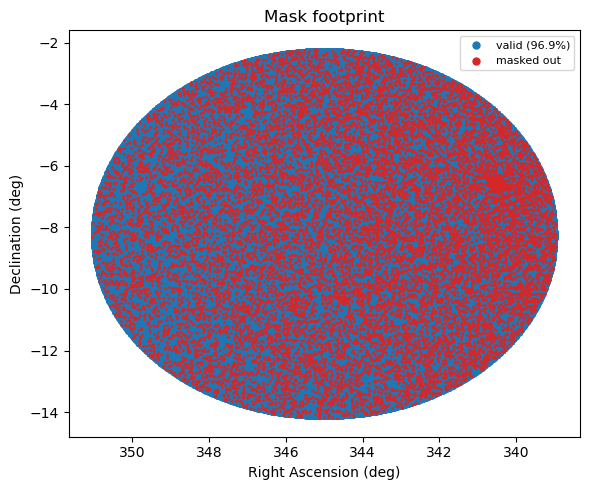

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(mask_ra[valid_mask], mask_dec[valid_mask], s=1, c='C0',
          label='valid ({:.1f}%)'.format(100 * valid_mask.mean()))
ax.scatter(mask_ra[~valid_mask], mask_dec[~valid_mask], s=1, c='C3', label='masked out')
ax.set_xlabel('Right Ascension (deg)')
ax.set_ylabel('Declination (deg)')
ax.invert_xaxis()
ax.legend(fontsize=8, markerscale=5)
ax.set_title('Mask footprint')
plt.tight_layout()
plt.show()


### 3.5. Build the systematics templates

Pixelize each systematic at `DIAG_NSIDE` (256-512): the i-band Butler maps, stellar density,
and E(B-V), which has no dedicated Butler map so it is built here by averaging the per-object
`ebv` column (pulled with the Object query) in each pixel.

In [16]:
def weighted_sum_in_pixels(ra, dec, values, pix_grid):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(pix_grid, pix), 0, len(pix_grid) - 1)
    found = pix_grid[idx] == pix
    sums = np.zeros(len(pix_grid))
    counts = np.zeros(len(pix_grid))
    np.add.at(sums, idx[found], values[found])
    np.add.at(counts, idx[found], 1)
    return sums, counts


ebv_sum, ebv_count = weighted_sum_in_pixels(obj_df_renamed['ra'].values, obj_df_renamed['dec'].values,
                                            obj_df_renamed['ebv'].values, mask_pix)
with np.errstate(invalid='ignore', divide='ignore'):
    ebv_native = np.where(ebv_count > 0, ebv_sum / np.maximum(ebv_count, 1), np.nan)

systematic_labels = {
    'i_depth': 'i-band depth (maglim)',
    'ebv': 'E(B-V)',
    'stellar_density': 'stellar density (/deg^2)',
}
systematics_native = {
    'i_depth': i_maglim_vals,
    'ebv': ebv_native,
    'stellar_density': star_density,
}
if FETCH_FULL_SYSTEMATICS:
    systematic_labels.update({
        'i_psf_size': 'i-band PSF size',
        'i_sky_noise': 'i-band sky noise',
        'i_exptime': 'i-band exposure time',
    })
    systematics_native.update({
        'i_psf_size': i_psfsize_vals,
        'i_sky_noise': i_skynoise_vals,
        'i_exptime': i_exptime_vals,
    })
print('Systematics templates:', list(systematic_labels.keys()))

systematics_valid = {k: v[valid_mask] for k, v in systematics_native.items()}


def degrade_pix(pix_fine, nside_fine, nside_coarse):
    shift = 2 * int(round(np.log2(nside_fine / nside_coarse)))
    return pix_fine >> shift


diag_pix_of_valid = degrade_pix(valid_pix, MASK_NSIDE, DIAG_NSIDE)
diag_unique, diag_inverse = np.unique(diag_pix_of_valid, return_inverse=True)
diag_area_deg2 = hp.nside2pixarea(DIAG_NSIDE, degrees=True)


def mean_per_diag_pixel(values):
    valid = ~np.isnan(values)
    sums = np.bincount(diag_inverse[valid], weights=values[valid], minlength=len(diag_unique))
    counts = np.bincount(diag_inverse[valid], minlength=len(diag_unique))
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(counts > 0, sums / np.maximum(counts, 1), np.nan)


diag_values = {name: mean_per_diag_pixel(systematics_valid[name]) for name in systematic_labels}
valid_native_count_diag = np.bincount(diag_inverse, minlength=len(diag_unique))
diag_area_per_pix_deg2 = valid_native_count_diag * pixel_area_deg2


Systematics templates: ['i_depth', 'ebv', 'stellar_density', 'i_psf_size', 'i_sky_noise', 'i_exptime']


In [17]:
def galaxy_density_diag(sel=None):
    """Per-diagnostic-pixel galaxy count and mean density, optionally for a boolean subset
    of `galaxies` (e.g. one tomographic bin); reused for the full sample here and per-bin
    in Section 5."""
    ra = galaxies['ra'].values if sel is None else galaxies['ra'][sel].values
    dec = galaxies['dec'].values if sel is None else galaxies['dec'][sel].values
    counts_native = count_in_pixels(ra, dec, mask_pix)
    counts_native_valid = counts_native[valid_mask]
    n_gal = np.bincount(diag_inverse, weights=counts_native_valid, minlength=len(diag_unique))
    mean_dens = n_gal.sum() / diag_area_per_pix_deg2.sum()
    return n_gal, mean_dens


n_gal_diag, mean_density = galaxy_density_diag()
print('Mean galaxy density: {:.2f} / deg^2 over {} diagnostic pixels at nside={}'.format(
    mean_density, len(diag_unique), DIAG_NSIDE))

N_SYS_BINS = 8


def density_ratio_trend(sys_values, n_gal, area, mean_dens, nbins=N_SYS_BINS):
    """n_gal/<n_gal> in nbins percentile bins of a systematic, for the classic DES figure."""
    good = ~np.isnan(sys_values) & (area > 0)
    edges = np.nanpercentile(sys_values[good], np.linspace(0, 100, nbins + 1))
    edges[0] -= 1e-6
    edges[-1] += 1e-6
    bin_idx = np.clip(np.digitize(sys_values[good], edges) - 1, 0, nbins - 1)
    x, y, yerr = [], [], []
    for k in range(nbins):
        sel = bin_idx == k
        if not np.any(sel):
            continue
        n_tot = n_gal[good][sel].sum()
        a_tot = area[good][sel].sum()
        dens = (n_tot / a_tot) / mean_dens
        err = dens / np.sqrt(max(n_tot, 1))
        x.append(np.average(sys_values[good][sel]))
        y.append(dens)
        yerr.append(err)
    return np.array(x), np.array(y), np.array(yerr)


Mean galaxy density: 1594.91 / deg^2 over 8797 diagnostic pixels at nside=512


### 3.6. Fit systematics weights

Fit a linear model for the fractional overdensity in terms of the (standardized)
systematics at `DIAG_NSIDE`, weighted by the unmasked area per diagnostic pixel. Each
galaxy's weight is `1 / (1 + sum_i a_i * s_i)`, evaluated at its own position. The plot below
compares the `n_gal / <n>` trend before and after weighting, for each systematic — the
classic DES validation figure, shown once with both curves rather than twice.

In [18]:
sys_names = list(systematic_labels.keys())
X_raw = np.column_stack([diag_values[name] for name in sys_names])
good = (diag_area_per_pix_deg2 > 0) & ~np.isnan(X_raw).any(axis=1)

X_mean = X_raw[good].mean(axis=0)
X_std = X_raw[good].std(axis=0)
X_std[X_std == 0] = 1.0
X_norm = (X_raw - X_mean) / X_std

y = (n_gal_diag / diag_area_per_pix_deg2) / mean_density - 1.0
area_weight = diag_area_per_pix_deg2

A = X_norm[good] * np.sqrt(area_weight[good])[:, None]
b_ = y[good] * np.sqrt(area_weight[good])
coeffs, _, _, _ = np.linalg.lstsq(A, b_, rcond=None)
print('Fitted systematics coefficients:')
for name, c in zip(sys_names, coeffs):
    print('  {:<16s} {:+.4f}'.format(name, c))


Fitted systematics coefficients:
  i_depth          +0.0152
  ebv              -0.0203
  stellar_density  -0.0091
  i_psf_size       -0.0056
  i_sky_noise      +0.0345
  i_exptime        -0.0237


In [19]:
def lookup_valid(values_at_valid_pix, ra, dec):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(valid_pix, pix), 0, len(valid_pix) - 1)
    found = valid_pix[idx] == pix
    out = np.full(len(pix), np.nan)
    out[found] = values_at_valid_pix[idx[found]]
    return out


gal_ra = galaxies['ra'].values
gal_dec = galaxies['dec'].values
gal_sys = {
    'i_depth': maglim_map.get_values_pos(gal_ra, gal_dec),
    'ebv': galaxies['ebv'].values,
    'stellar_density': lookup_valid(systematics_valid['stellar_density'], gal_ra, gal_dec),
}
if FETCH_FULL_SYSTEMATICS:
    gal_sys.update({
        'i_psf_size': psfsize_map.get_values_pos(gal_ra, gal_dec),
        'i_sky_noise': skynoise_map.get_values_pos(gal_ra, gal_dec),
        'i_exptime': exptime_map.get_values_pos(gal_ra, gal_dec),
    })
X_gal = np.column_stack([gal_sys[name] for name in sys_names])
X_gal_norm = (X_gal - X_mean) / X_std
model = 1.0 + X_gal_norm @ coeffs
galaxies['weight'] = 1.0 / np.clip(model, 0.5, 2.0)
print('Weight stats: min {:.3f}, max {:.3f}, mean {:.3f}'.format(
    galaxies['weight'].min(), galaxies['weight'].max(), galaxies['weight'].mean()))


Weight stats: min 0.710, max 1.340, mean 1.003


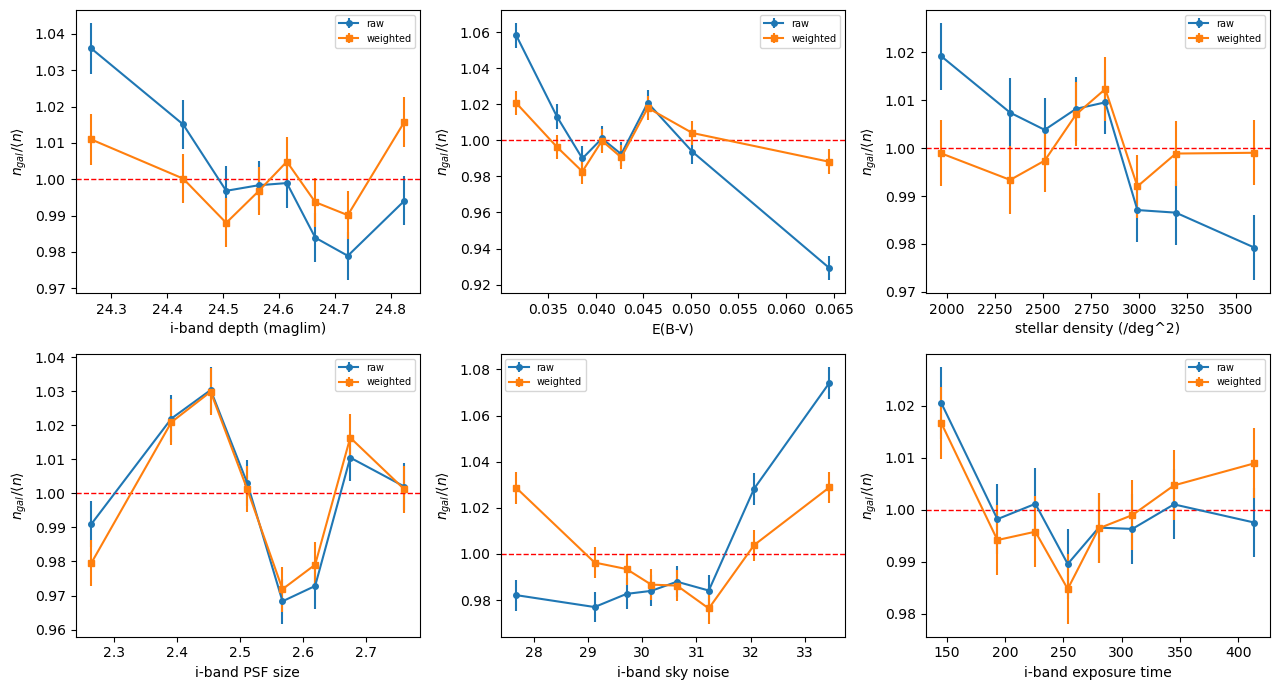

In [20]:
gal_weight_full = np.zeros(len(mask_pix))
pix = pixels_at(gal_ra, gal_dec)
idx = np.clip(np.searchsorted(mask_pix, pix), 0, len(mask_pix) - 1)
found = mask_pix[idx] == pix
np.add.at(gal_weight_full, idx[found], galaxies['weight'].values[found])
gal_weight_valid = gal_weight_full[valid_mask]
n_gal_diag_w = np.bincount(diag_inverse, weights=gal_weight_valid, minlength=len(diag_unique))
mean_density_w = n_gal_diag_w.sum() / diag_area_per_pix_deg2.sum()

n_sys = len(systematic_labels)
ncols = min(3, n_sys)
nrows = int(np.ceil(n_sys / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.5 * nrows), squeeze=False)
axes = axes.flatten()
for ax, (name, label) in zip(axes, systematic_labels.items()):
    x_r, y_r, yerr_r = density_ratio_trend(diag_values[name], n_gal_diag, diag_area_per_pix_deg2, mean_density)
    x_w, y_w, yerr_w = density_ratio_trend(diag_values[name], n_gal_diag_w, diag_area_per_pix_deg2, mean_density_w)
    ax.errorbar(x_r, y_r, yerr=yerr_r, fmt='o-', ms=4, label='raw')
    ax.errorbar(x_w, y_w, yerr=yerr_w, fmt='s-', ms=4, label='weighted')
    ax.axhline(1.0, color='r', ls='--', lw=1)
    ax.set_xlabel(label)
    ax.set_ylabel(r'$n_{gal}/\langle n \rangle$')
    ax.legend(fontsize=7)
for ax in axes[n_sys:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## 4. Angular correlation function

Generate randoms matching the mask, then measure the raw and weighted w(theta) per
tomographic bin with TreeCorr.

### 4.1. Randoms

Generate randoms uniformly over the unmasked footprint: pick a random valid `MASK_NSIDE`
pixel, then jitter to a random sub-pixel position `RAND_OVERSAMPLE` times finer, which
approximates continuous uniform sampling within the pixel. The same random catalog is reused
for every tomographic bin, since the mask does not depend on redshift.

In [21]:
N_RANDOMS = min(MAX_RANDOMS, RAND_FACTOR * len(galaxies))
RAND_OVERSAMPLE = 16
rand_nside = MASK_NSIDE * RAND_OVERSAMPLE
sub_factor2 = RAND_OVERSAMPLE**2

rng = np.random.default_rng(0)
chosen_coarse = valid_pix[rng.integers(0, len(valid_pix), size=N_RANDOMS)]
sub_offset = rng.integers(0, sub_factor2, size=N_RANDOMS)
fine_pix = chosen_coarse.astype(np.int64) * sub_factor2 + sub_offset
rand_ra, rand_dec = hp.pix2ang(rand_nside, fine_pix, nest=True, lonlat=True)
print(N_RANDOMS, 'randoms generated ({:.1f}x the galaxy count)'.format(N_RANDOMS / len(galaxies)))


2000000 randoms generated (11.4x the galaxy count)


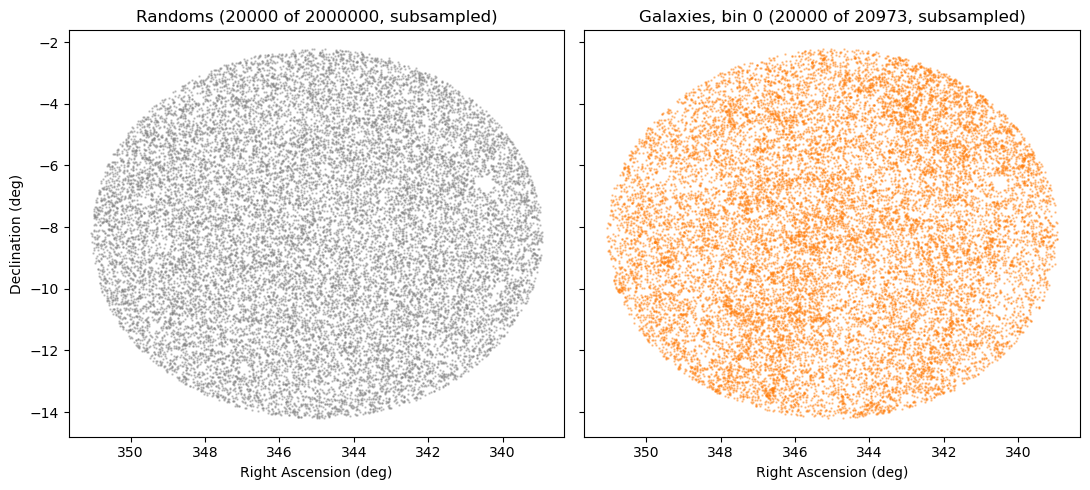

In [22]:
EXAMPLE_ZBIN = 0
N_PLOT_SUB = 20000

rng_plot = np.random.default_rng(1)
rand_sub = rng_plot.choice(len(rand_ra), size=min(N_PLOT_SUB, len(rand_ra)), replace=False)

gal_sel = (galaxies['zbin'] == EXAMPLE_ZBIN).values
gal_ra_bin = galaxies['ra'][gal_sel].values
gal_dec_bin = galaxies['dec'][gal_sel].values
gal_sub = rng_plot.choice(len(gal_ra_bin), size=min(N_PLOT_SUB, len(gal_ra_bin)), replace=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
ax1.plot(rand_ra[rand_sub], rand_dec[rand_sub], '.', ms=1.5, alpha=0.4, color='grey')
ax1.set_title('Randoms ({} of {}, subsampled)'.format(len(rand_sub), N_RANDOMS))
ax1.set_xlabel('Right Ascension (deg)')
ax1.set_ylabel('Declination (deg)')
ax1.invert_xaxis()

ax2.plot(gal_ra_bin[gal_sub], gal_dec_bin[gal_sub], '.', ms=1.5, alpha=0.4, color='C1')
ax2.set_title('Galaxies, bin {} ({} of {}, subsampled)'.format(
    EXAMPLE_ZBIN, len(gal_sub), len(gal_ra_bin)))
ax2.set_xlabel('Right Ascension (deg)')
plt.tight_layout()
plt.show()


### 4.2. Compute w(theta), raw and weighted

Landy-Szalay estimator, `w = (DD - 2*DR + RR) / RR`, per tomographic bin against the shared
random catalog, both unweighted and using the Section 3.6 weight.

The error bars plotted throughout this section are TreeCorr's internal shot-noise estimate
from the pair counts alone (essentially Poisson, `~1/sqrt(DD)`) — they do not include sample
variance from measuring a single patch. Don't read too much into bin-to-bin scatter beyond
what they imply, especially at the largest separations, where real analyses would use
jackknife or bootstrap resampling over sub-regions of the footprint instead.

In [23]:
rand_cat = treecorr.Catalog(ra=rand_ra, dec=rand_dec, ra_units='deg', dec_units='deg')
rr = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                            nbins=TC_NBINS, sep_units='arcmin')
rr.process(rand_cat)


def compute_wtheta(ra, dec, w=None):
    cat = treecorr.Catalog(ra=ra, dec=dec, w=w, ra_units='deg', dec_units='deg')
    dd = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                                nbins=TC_NBINS, sep_units='arcmin')
    dr = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                                nbins=TC_NBINS, sep_units='arcmin')
    dd.process(cat)
    dr.process(cat, rand_cat)
    xi, varxi = dd.calculateXi(rr=rr, dr=dr)
    return dd.meanr, xi, np.sqrt(varxi), dd.npairs, dr.npairs


raw_results = {}
weighted_results = {}
for b in range(N_ZBINS):
    sel = (galaxies['zbin'] == b).values
    raw_results[b] = compute_wtheta(galaxies['ra'][sel].values, galaxies['dec'][sel].values)
    theta, xi, err, _, _ = compute_wtheta(galaxies['ra'][sel].values, galaxies['dec'][sel].values,
                                          w=galaxies['weight'][sel].values)
    weighted_results[b] = (theta, xi, err)
    print('bin {}: {} galaxies'.format(b, sel.sum()))


bin 0: 20973 galaxies
bin 1: 55329 galaxies
bin 2: 44254 galaxies
bin 3: 54145 galaxies


### 4.3. Pair counts (DD, DR, RR)

The raw pair counts TreeCorr combines into the Landy-Szalay estimator above, per
tomographic bin. RR is shared across bins since it only depends on the (redshift-independent)
random catalog.

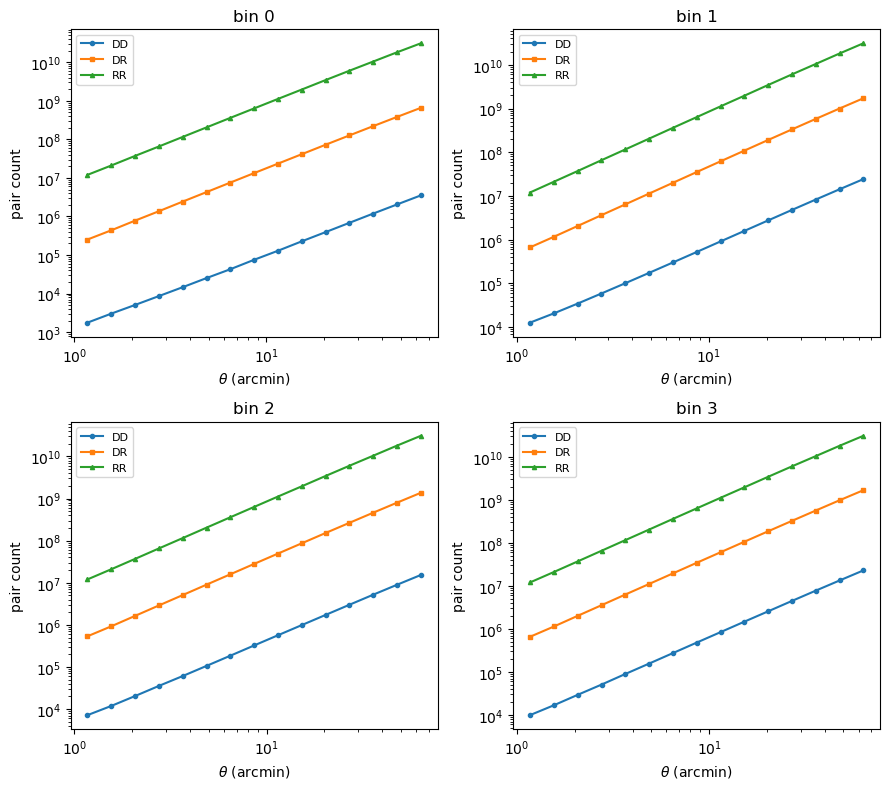

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
axes = axes.flatten()
for b, ax in enumerate(axes):
    theta, xi, err, dd_pairs, dr_pairs = raw_results[b]
    ax.plot(theta, dd_pairs, 'o-', ms=3, label='DD')
    ax.plot(theta, dr_pairs, 's-', ms=3, label='DR')
    ax.plot(theta, rr.npairs, '^-', ms=3, label='RR')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('bin {}'.format(b))
    ax.set_xlabel(r'$\theta$ (arcmin)')
    ax.set_ylabel('pair count')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 4.4. w(theta): raw vs. weighted

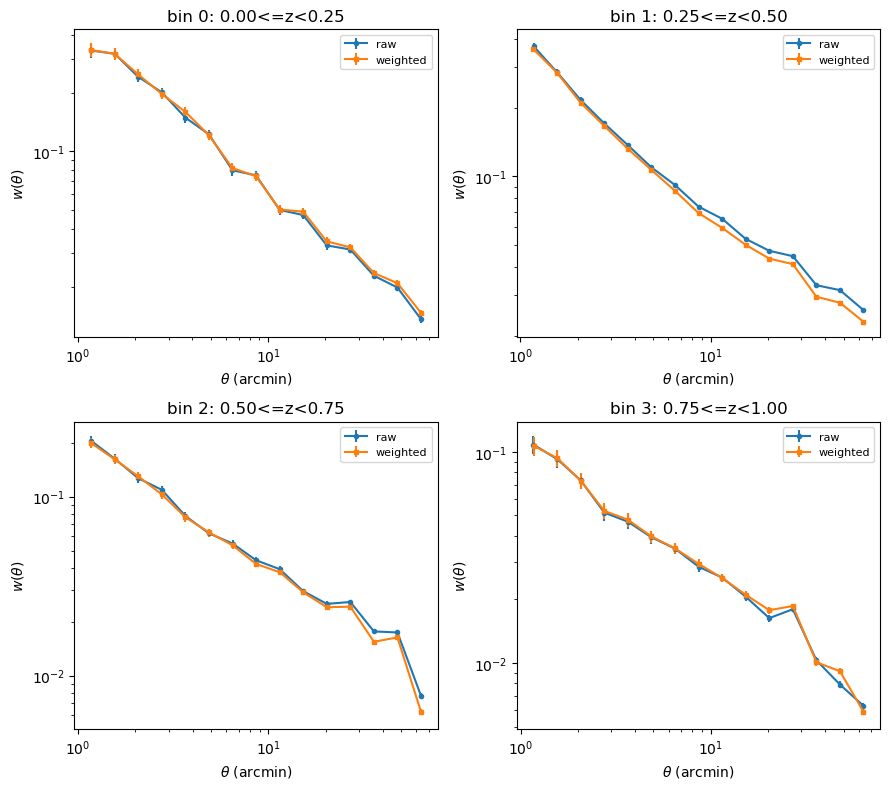

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
axes = axes.flatten()
for b, ax in enumerate(axes):
    theta_r, xi_r, err_r, _, _ = raw_results[b]
    theta_w, xi_w, err_w = weighted_results[b]
    ax.errorbar(theta_r, xi_r, yerr=err_r, fmt='o-', ms=3, label='raw')
    ax.errorbar(theta_w, xi_w, yerr=err_w, fmt='s-', ms=3, label='weighted')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('bin {}: {:.2f}<=z<{:.2f}'.format(b, Z_EDGES[b], Z_EDGES[b + 1]))
    ax.set_xlabel(r'$\theta$ (arcmin)')
    ax.set_ylabel(r'$w(\theta)$')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 4.5. Redshift evolution of the corrected w(theta)

The weighted w(theta) from all four tomographic bins, together, to compare clustering shape
and amplitude across redshift directly.

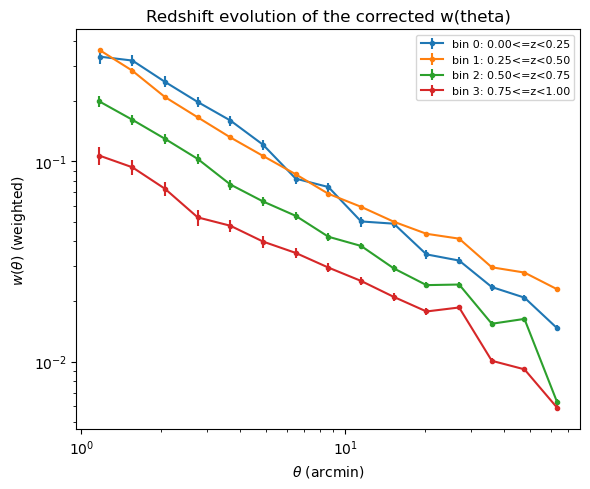

In [26]:
fig, ax = plt.subplots(figsize=(6, 5))
for b in range(N_ZBINS):
    theta, xi, err = weighted_results[b]
    ax.errorbar(theta, xi, yerr=err, fmt='o-', ms=3,
               label='bin {}: {:.2f}<=z<{:.2f}'.format(b, Z_EDGES[b], Z_EDGES[b + 1]))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\theta$ (arcmin)')
ax.set_ylabel(r'$w(\theta)$ (weighted)')
ax.set_title('Redshift evolution of the corrected w(theta)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 5. Angular power spectrum

A harmonic-space view of the same clustering signal, per tomographic bin: the angular power
spectrum C(ell), raw and with systematics-template deprojection, measured properly with
NaMaster (full MASTER-algorithm deconvolution, not just the amplitude-only `w2` correction a
naive `healpy.anafast` pseudo-C(ell) would give). That naive version is still computed, for
the full non-tomographic sample only, and shown as a light background reference in the final
plot — not as its own result.

In [27]:
# Naive pseudo-C(ell) for the full (non-tomographic) sample only, kept purely as a light
# background reference in the final plot below. The `w2` correction only fixes amplitude,
# not mode coupling, so this isn't trustworthy on its own -- see the NaMaster treatment.
def overdensity_cl(n_gal_per_pix, mean_dens):
    npix_full = hp.nside2npix(DIAG_NSIDE)
    mask_full = np.zeros(npix_full)
    mask_full[diag_unique] = diag_area_per_pix_deg2 / diag_area_deg2

    delta_full = np.zeros(npix_full)
    delta_full[diag_unique] = (n_gal_per_pix / diag_area_per_pix_deg2) / mean_dens - 1.0

    weighted_delta_nest = delta_full * mask_full
    weighted_delta_ring = hp.reorder(weighted_delta_nest, n2r=True)

    cl_pseudo = hp.anafast(weighted_delta_ring)
    w2 = np.mean(mask_full**2)
    return cl_pseudo / w2


cl_raw_full = overdensity_cl(n_gal_diag, mean_density)
ell = np.arange(len(cl_raw_full))

# Below this ell, the patch is smaller than (or comparable to) the angular scale itself, so
# the mask's own window function dominates over any real signal.
ELL_MIN = max(2, int(np.ceil(180.0 / (2 * RADIUS_DEG))))
print('ELL_MIN = {} (patch diameter {:.1f} deg)'.format(ELL_MIN, 2 * RADIUS_DEG))


ELL_MIN = 15 (patch diameter 12.0 deg)


### 5.1. Proper deconvolution and template deprojection with NaMaster

[NaMaster](https://namaster.readthedocs.io/) (`pymaster`) does the full MASTER-algorithm
mode-coupling deconvolution properly, and — closer to the point of this comparison — can
deproject contaminant templates directly from the field in harmonic space, the natural
power-spectrum analog of the per-galaxy weight fit in Section 3.6. Reusing the exact same
`diag_values[name]` arrays (same pixelization, same systematics) as that fit keeps the two
treatments as directly comparable as possible. The mode-coupling matrix only depends on the
mask, so it's computed once and reused for every tomographic bin.

`pymaster` is not part of the shared environment; if the import below fails, run
`pip install --user pymaster` once (it builds from source, a couple of minutes) and restart
the kernel.

In [28]:
try:
    import pymaster as nmt
except ImportError:
    raise ImportError(
        "pymaster (NaMaster) is not installed. Run once, in a terminal or a notebook cell:\n"
        "  !pip install --user pymaster\n"
        "then restart the kernel."
    )


def full_map_at_diag(values_at_valid_diag, fill=0.0):
    m = np.full(hp.nside2npix(DIAG_NSIDE), fill)
    m[diag_unique] = np.where(np.isnan(values_at_valid_diag), fill, values_at_valid_diag)
    return m


mask_full_nest = full_map_at_diag(diag_area_per_pix_deg2 / diag_area_deg2)
mask_full_ring = hp.reorder(mask_full_nest, n2r=True)

template_maps_ring = [[hp.reorder(full_map_at_diag(diag_values[name]), n2r=True)]
                      for name in sys_names]
print('Using', len(sys_names), 'contaminant templates:', sys_names)

fsky = np.mean(mask_full_ring)
print('fsky = {:.2e} (1/fsky = {:.0f}) — sets how wide the ell bins need to be below'.format(
    fsky, 1.0 / fsky))


Using 6 contaminant templates: ['i_depth', 'ebv', 'stellar_density', 'i_psf_size', 'i_sky_noise', 'i_exptime']
fsky = 2.66e-03 (1/fsky = 377) — sets how wide the ell bins need to be below


In [29]:
# Linear, uniform-width ell bins look "messy" here: the mode-coupling matrix for a mask this
# small is close to singular, and a few ell ranges (especially near the ELL_MIN cutoff) are
# much less constrained than others, so uniform bins leave some of them numerically unstable
# (wild, often-negative bandpowers) while over-resolving ranges that didn't need it. Binning
# log-spaced in ell matches typical S/N per ell better (fewer, wider bins at low ell; more,
# narrower bins at high ell where there are many more independent modes per unit ell), while
# a minimum-width floor (same `0.08 / fsky` scaling used before) keeps every bin numerically
# stable regardless of where it falls.
NMT_BIN_FLOOR = max(20, int(np.ceil(0.08 / fsky)))
N_LOG_BINS = 16
lmax = 3 * DIAG_NSIDE - 1

raw_edges = np.unique(np.round(np.geomspace(ELL_MIN, lmax + 1, N_LOG_BINS + 1)).astype(int))
edges = [raw_edges[0]]
for e in raw_edges[1:]:
    if e - edges[-1] >= NMT_BIN_FLOOR:
        edges.append(e)
if edges[-1] != raw_edges[-1]:
    edges[-1] = raw_edges[-1]
edges = np.array(edges)

nmt_bins = nmt.NmtBin.from_edges(edges[:-1], edges[1:])
ell_nmt = nmt_bins.get_effective_ells()

# The mode-coupling matrix depends only on the mask, not on any particular field's data, so
# build it once from a placeholder field and reuse it for every tomographic bin below.
field_for_matrix = nmt.NmtField(mask_full_ring, [np.zeros_like(mask_full_ring)], spin=0)
workspace = nmt.NmtWorkspace()
workspace.compute_coupling_matrix(field_for_matrix, field_for_matrix, nmt_bins)

print('{} log-spaced bandpowers (floor width {}) from ell={} to ell={}'.format(
    nmt_bins.get_n_bands(), NMT_BIN_FLOOR, edges[0], edges[-1]))


11 log-spaced bandpowers (floor width 31) from ell=15 to ell=1536


In [30]:
cl_raw_zbins = {}
cl_deproj_zbins = {}
for b in range(N_ZBINS):
    sel = (galaxies['zbin'] == b).values
    n_gal_b, mean_density_b = galaxy_density_diag(sel)
    delta_b_nest = full_map_at_diag((n_gal_b / diag_area_per_pix_deg2) / mean_density_b - 1.0)
    delta_b_ring = hp.reorder(delta_b_nest, n2r=True)

    field_b_plain = nmt.NmtField(mask_full_ring, [delta_b_ring], spin=0)
    cl_raw_zbins[b] = workspace.decouple_cell(nmt.compute_coupled_cell(field_b_plain, field_b_plain))[0]

    field_b_deproj = nmt.NmtField(mask_full_ring, [delta_b_ring], spin=0, templates=template_maps_ring)
    cl_deproj_zbins[b] = workspace.decouple_cell(
        nmt.compute_coupled_cell(field_b_deproj, field_b_deproj))[0]

    frac_neg = np.mean(cl_deproj_zbins[b] < 0)
    print('bin {}: {} galaxies{}'.format(b, sel.sum(),
         ' -- Warning: {:.0%} of deprojected bandpowers negative'.format(frac_neg)
         if frac_neg > 0.1 else ''))


bin 0: 20973 galaxies
bin 1: 55329 galaxies
bin 2: 44254 galaxies
bin 3: 54145 galaxies


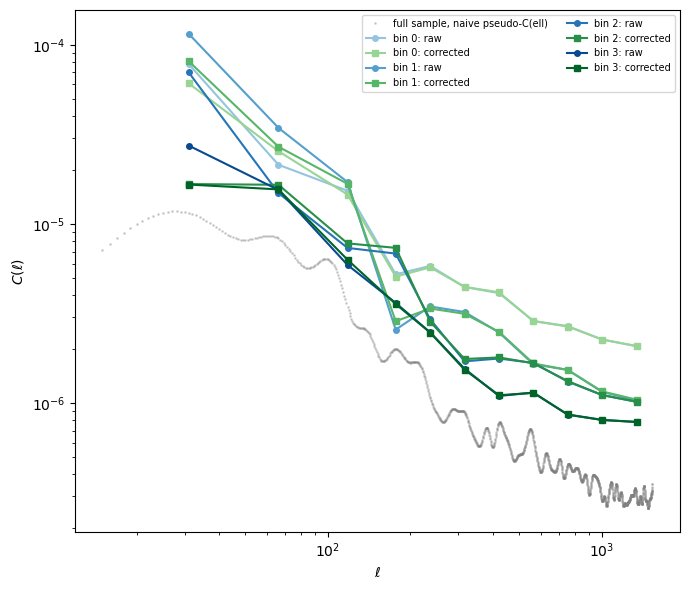

In [31]:
blues = plt.cm.Blues(np.linspace(0.4, 0.9, N_ZBINS))
greens = plt.cm.Greens(np.linspace(0.4, 0.9, N_ZBINS))

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(ell[ELL_MIN:], cl_raw_full[ELL_MIN:], '.', ms=2, alpha=0.3, color='grey',
       label='full sample, naive pseudo-C(ell)', zorder=0)
for b in range(N_ZBINS):
    ax.plot(ell_nmt, cl_raw_zbins[b], 'o-', ms=4, color=blues[b],
           label='bin {}: raw'.format(b))
    ax.plot(ell_nmt, cl_deproj_zbins[b], 's-', ms=4, color=greens[b],
           label='bin {}: corrected'.format(b))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\ell$')
ax.set_ylabel(r'$C(\ell)$')
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


## Next steps

- Set `RADIUS_DEG` (Section 1.1) to one of the presets noted there, or grow it further toward
  the full footprint.
- Set `FETCH_FULL_SYSTEMATICS = True` (Section 1.1) to fetch all 7 Butler maps and use the
  full 6-template set in Sections 3 and 5; `False` fetches only the i-band depth map (enough
  for a properly masked w(theta), with fewer systematics templates). Either way, map fetches
  are cached under `MAP_CACHE_DIR`, so switching the flag back and forth, or re-running with
  the same region, doesn't re-pay the slow Butler I/O for maps already fetched.
- `USE_PRECOMPUTED_DATA` (Section 1.3) loads `galaxies`/`obj_df_renamed` from `data/` instead
  of re-running Section 2 live, if a cache matching the current parameters exists there. Run
  `prepare_data.py` once (ideally for the full region) to produce that cache; a live run also
  writes it automatically.
- The systematics diagnostics and weight fit in Section 3.6 use the full (non-tomographic)
  MagLim sample; redshift-dependent systematics would call for per-bin versions.
- The linear weight model is the simplest DES-style approach; an iterative decontamination
  scheme would refit on the residuals of this one.
- `galaxies` columns: `objectId`, `ra`, `dec`, `i_mag`, `z_phot`, `zbin`, `ebv`, `weight`.